# Multimeter: R_eff(i, j) Between Arbitrary Nodes


## Before you start

Run the notebook from top to bottom in a fresh runtime. Saved outputs do
not initialize variables. After changing a utility module, re-run the
imports cell in Section 1; restart the runtime and run all cells if stale
imports persist. Once setup is complete, use the controls in Section 5 to
measure new node pairs without rerunning the notebook.

The primary resistance model is `R_edge = R0 * L_edge`, as in
`distance_dependent_resistance.ipynb` and the `(N, a, d)` sweep. The uniform
model, `R_edge = R0`, is available for comparison in Sections 5 and 8.

The workflow checks closed-form circuits, generates a seeded percolating
network, measures point pairs, and samples resistance in distance shells
around one reference node. It then repeats the shell measurements across
five seeds and compares point probes with whole-face terminals.


---
## 1. Setup and imports

In [36]:
# Environment and path setup is handled in the next cell.

In [37]:
import sys
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

FOLDER_ID = "1EfMQ_Fva3PnYxqtXSW8an_htQ8-B6lOs"

try:
    from google.colab import drive
    drive.mount('/content/drive')

    # Pastas compartilhadas com atalho aparecem aqui pelo ID
    matches = glob.glob(f"/content/drive/.shortcut-targets-by-id/{FOLDER_ID}/*")
    if matches:
        utils_path = matches[0]
    else:
        # Fallback: troque "NOME_DA_PASTA" pelo nome real da pasta
        utils_path = "/content/drive/MyDrive/NOME_DA_PASTA"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(os.listdir(utils_path))  # confere se os arquivos aparecem

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment: Google Colab
Utils path: /content/drive/.shortcut-targets-by-id/1EfMQ_Fva3PnYxqtXSW8an_htQ8-B6lOs/utils
['filtered_paths.py', 'utility_reset.py', 'region_checks.py', 'plotting_old.py', 'pdf_generator.py', 'rebuild_experiments.py', 'test_merge.py', 'result_exporter.py', 'plotting.py', 'test_networks.py', 'pipeline_utils_src.py', 'self_loop_utils.py', 'loop_topology_utils.py', 'node_loop_visualization.py', 'node_loop_test_runner.py', 'self_loops.py', 'admittance_checks.py', 'edge_discovery.py', 'boundary_utils.py', 'experiment_manager.py', 'intersection_utils_3d.py', 'path_analysis.py', 'pruning.py', 'multi_terminal_solver.py', 'network_visualization_3d.py', 'test_multimeter.py', 'test_percolation_3d.py', 'README.md', 'impedance_calculator.py', 'laplacian_utils.py', '__pycache__ (1)', 'multimeter.py', 'random_network_batch.py', 'point_generator.py.

In [38]:
import importlib
import impedance_calculator as impedance_calculator_module
import multimeter as multimeter_module
import network_visualization as network_visualization_module
import pipeline_utils as pipeline_utils_module
import laplacian_utils as laplacian_utils_module

# Force a fresh reload of the utils/*.py files this notebook depends on,
# so re-running just this cell (instead of a full Runtime -> Restart) picks
# up any code changes made to them since this session started. Plain
# `import` only runs a module's code once per session; without this,
# re-running a cell after a file changes still uses the OLD version already
# cached in memory, and calling a newly added function/argument fails with
# a confusing TypeError.
#
# impedance_calculator goes FIRST because the others sit on top of it:
# pipeline_utils.distance_dependent_impedance calls its build_merge_node_mapping
# and merged_edge_true_lengths, and multimeter goes through its calculate().
# Reloading the upper layers while leaving this one cached is exactly what
# produces "unexpected keyword argument 'edge_lengths'" or "cannot import name
# 'merged_edge_true_lengths'": new callers talking to an old callee.
importlib.reload(impedance_calculator_module)
importlib.reload(multimeter_module)
importlib.reload(network_visualization_module)
importlib.reload(pipeline_utils_module)
importlib.reload(laplacian_utils_module)

from pipeline_utils import generate_percolating_network, distance_dependent_impedance
from multimeter import (measure_r_eff, onion_layers, run_onion_protocol,
                       run_onion_protocol_pinv, probe_summary, format_probe_summary,
                       edge_color_field)
from laplacian_utils import effective_resistance_from_reference, effective_resistance_pinv
from network_visualization import (plot_network_colored_by_voltage,
                                   plot_network_colored_by_resistance,
                                   plot_network_colored_by_node_field,
                                   plot_r_eff_vs_distance)
from experiment_manager import setup_experiment
import ipywidgets as widgets
from IPython.display import display, clear_output

exp_manager = setup_experiment()

EXPERIMENT CONFIGURATION
  Environment: Google Colab
  Experiment #: 3
  Timestamp: 20261027_143816
  Results directory: /content/drive/MyDrive/ColabProject/experiments/exp_3



In [39]:
def build_graph_from_segments(n_nodes, segment_to_nodes):
    """ImpedanceCalculator's constructor expects a `graph` list, but
    measure_r_eff's two-point solve never actually reads it; this just
    builds one of the right shape from segment_to_nodes, the same way
    path_analysis.rebuild_local_graph does."""
    g = [[] for _ in range(n_nodes)]
    for e, (n1, n2) in segment_to_nodes.items():
        g[n1].append(e)
        g[n2].append(e)
    return g

---
## 2. Sanity check: validate against known closed-form networks

Two hand-built networks where R_eff can be computed by hand, so a mismatch
here would mean the multimeter itself is broken before it ever touches a
real percolating network.

Both are solved under the **distance-dependent model** (`R_edge = R0 · L_edge`),
the model used throughout this notebook, and both are built with deliberately
*unequal* edge lengths so their closed-form answers depend on those lengths.
A uniform-`k` solve would give different numbers on the same two circuits, so
these checks fail loudly if the length dependence ever stops reaching the
solver.

In [40]:
print("="*70)
print("4-node ring, distance-dependent resistors (R_edge = R0 * length, R0 = 1)")
print("="*70)

# Deliberately a RECTANGLE, not a square: edge lengths alternate 2, 1, 2, 1, so
# the closed-form answers below depend on the edge lengths. A uniform-k solve
# on this same ring would give 1.0000 and 0.7500 instead, so this test fails
# loudly if the distance dependence ever stops reaching the solver.
R0_test = 1.0
ring_intersections = [[0.0, 0.0], [2.0, 0.0], [2.0, 1.0], [0.0, 1.0]]
ring_segment_to_nodes = {0: (0, 1), 1: (1, 2), 2: (2, 3), 3: (3, 0)}
ring_graph = build_graph_from_segments(len(ring_intersections), ring_segment_to_nodes)

r_opposite = measure_r_eff(ring_intersections, ring_graph, ring_segment_to_nodes, 0, 2,
                           k=R0_test, distance_dependent=True)
r_adjacent = measure_r_eff(ring_intersections, ring_graph, ring_segment_to_nodes, 0, 1,
                           k=R0_test, distance_dependent=True)

print(f"R_eff(0,2) opposite corners = {r_opposite['impedance']:.4f}  "
      f"(expected 1.5000: two arcs of 2+1=3 in parallel)")
print(f"R_eff(0,1) adjacent corners = {r_adjacent['impedance']:.4f}  "
      f"(expected 1.3333: the direct edge 2 in parallel with 1+2+1=4)")
assert abs(r_opposite['impedance'] - 1.5) < 1e-9
assert abs(r_adjacent['impedance'] - 4.0 / 3.0) < 1e-9

r_uniform_check = measure_r_eff(ring_intersections, ring_graph, ring_segment_to_nodes, 0, 2,
                                k=R0_test, distance_dependent=False)
print(f"(same pair under the uniform model, for contrast: {r_uniform_check['impedance']:.4f})")
assert abs(r_uniform_check['impedance'] - 1.0) < 1e-9
print("PASSED")

4-node ring, distance-dependent resistors (R_edge = R0 * length, R0 = 1)
R_eff(0,2) opposite corners = 1.5000  (expected 1.5000: two arcs of 2+1=3 in parallel)
R_eff(0,1) adjacent corners = 1.3333  (expected 1.3333: the direct edge 2 in parallel with 1+2+1=4)
(same pair under the uniform model, for contrast: 1.0000)
PASSED


In [41]:
print("="*70)
print("10-node series chain, UNEVEN spacing, distance-dependent resistors")
print("="*70)

# All ten nodes sit on the x axis with irregular gaps, so the chain from node 0
# to node n is a pure series of edges whose lengths differ: R_eff(0,n) must be
# R0 * (x_n - x_0), the total length travelled, not n * k. Uneven spacing is the
# point: under the uniform model every answer here would be n instead.
chain_x = [0.0, 0.05, 0.2, 0.35, 0.4, 0.6, 0.75, 0.8, 0.95, 1.0]
chain_intersections = [[x, 0.0] for x in chain_x]
chain_segment_to_nodes = {i: (i, i + 1) for i in range(9)}
chain_graph = build_graph_from_segments(len(chain_intersections), chain_segment_to_nodes)

all_passed = True
for n in range(1, 10):
    r = measure_r_eff(chain_intersections, chain_graph, chain_segment_to_nodes, 0, n,
                      k=R0_test, distance_dependent=True)
    expected = R0_test * (chain_x[n] - chain_x[0])
    ok = abs(r['impedance'] - expected) < 1e-9
    all_passed &= ok
    print(f"R_eff(0,{n}) = {r['impedance']:.4f}  (expected {expected:.4f} = R0 * total length, "
          f"{'OK' if ok else 'MISMATCH'})")

assert all_passed
print("PASSED")

10-node series chain, UNEVEN spacing, distance-dependent resistors
R_eff(0,1) = 0.0500  (expected 0.0500 = R0 * total length, OK)
R_eff(0,2) = 0.2000  (expected 0.2000 = R0 * total length, OK)
R_eff(0,3) = 0.3500  (expected 0.3500 = R0 * total length, OK)
R_eff(0,4) = 0.4000  (expected 0.4000 = R0 * total length, OK)
R_eff(0,5) = 0.6000  (expected 0.6000 = R0 * total length, OK)
R_eff(0,6) = 0.7500  (expected 0.7500 = R0 * total length, OK)
R_eff(0,7) = 0.8000  (expected 0.8000 = R0 * total length, OK)
R_eff(0,8) = 0.9500  (expected 0.9500 = R0 * total length, OK)
R_eff(0,9) = 1.0000  (expected 1.0000 = R0 * total length, OK)
PASSED


---
## 3. Generate a percolating network

Any percolating network works here. To probe a network from a previously
saved experiment instead of generating a fresh one, load it with
`experiment_manager.load_network(N)` and run it through
`pipeline_utils.run_full_pipeline` the way `test_random_network_impedance.ipynb`
does, then use its `pre_merge_intersections` / `pre_merge_segment_to_nodes`
below in place of `intersections` / `segment_to_nodes`.

In [42]:
N, a, R0 = 40, 0.6, 1000.0

# R0 is the resistance PER UNIT LENGTH: every edge below gets
# R_edge = R0 * L_edge, which is the model used from here to the end of this
# notebook (and by the (N, a, d) grid sweep). generate_percolating_network
# still solves its own whole-face impedance with a uniform k internally, so
# k_uniform=R0 just keeps that reference number on the same numeric scale;
# the distance-dependent whole-face value is recomputed right below it.
results, attempts = generate_percolating_network(N, a, k_uniform=R0, seed=11)

intersections = results['pre_merge_intersections']
segment_to_nodes = results['pre_merge_segment_to_nodes']
graph = build_graph_from_segments(len(intersections), segment_to_nodes)
source_nodes = results['pre_merge_source_nodes']
drain_nodes = results['pre_merge_drain_nodes']

whole_face_dd = distance_dependent_impedance(results, R0)['impedance']

print(f"Percolating network found after {attempts} attempt(s)")
print(f"  Nodes: {len(intersections)}   Edges: {len(segment_to_nodes)}")
print(f"  Whole-face source-drain R_eff, distance-dependent (R_edge = {R0:g} * L): "
      f"{whole_face_dd:.4f} Ohm")
print(f"  Whole-face source-drain R_eff, uniform (R_edge = {R0:g}): "
      f"{results['impedance']:.4f} Ohm  (reference only)")

Percolating network found after 1 attempt(s)
  Nodes: 170   Edges: 280
  Whole-face source-drain R_eff, distance-dependent (R_edge = 1000 * L): 152.6171 Ohm
  Whole-face source-drain R_eff, uniform (R_edge = 1000): 1945.8012 Ohm  (reference only)


---
## 4. Node IDs, for manually picking probes

Every scatter point below is annotated with its node index: pick any two for the interactive probe in the next section.

  [OK] Figure saved: node_ids.png


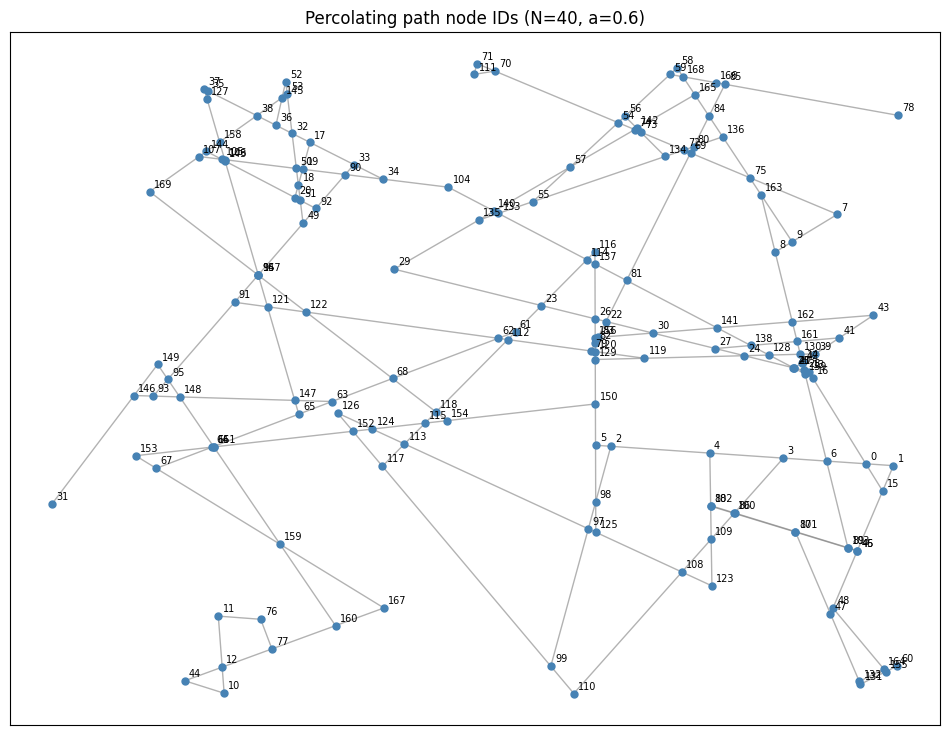

In [25]:
fig, ax = plt.subplots(figsize=(12, 9))
for n1, n2 in segment_to_nodes.values():
    x = [intersections[n1][0], intersections[n2][0]]
    y = [intersections[n1][1], intersections[n2][1]]
    ax.plot(x, y, color='gray', alpha=0.6, linewidth=1, zorder=1)
for i, (x, y) in enumerate(intersections):
    ax.scatter(x, y, c='steelblue', s=25, zorder=2)
    ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(3, 3), fontsize=7)
ax.set_title(f'Percolating path node IDs (N={N}, a={a})')
ax.set_xticks([])
ax.set_yticks([])
exp_manager.save_figure(fig, 'node_ids.png')
plt.show()

---
## 5. Interactive probe

Run the cell once, enter two node IDs from Section 4, and click **Measure**.
The selected nodes are ringed in black. Toggle **node IDs** to hide labels
or **detailed checks** to expand the numerical diagnostics.

The edge-colour choices are:

- **Current `|I|`**: the current routes for the selected probes.
- **Resistance `R0 * L_edge`**: the fixed edge resistances, independent of
  the probe pair under this model.
- **Power `I² * R`**: where energy is dissipated.

The result reports resistance, probe separation, the alternative model's
resistance, and the comparison with the cheapest single series path. The
checks compare the solve with `R_eff = eᵀL⁺e`, verify `R/L = R0` for the
distance-dependent model, and measure the largest KCL residual at a
non-probe node. Bright current routes should connect the probes; parallel
routes explain a resistance below the single-path bound.

The **model** dropdown switches between distance-dependent and uniform
edge resistances. Disconnected probes return `inf`. Scripted measurements
in the next cell use the same `multimeter.probe_summary` helper.


In [26]:
# Make sure Section 3 (network generation) has actually run in THIS session.
try:
    intersections
except NameError:
    raise RuntimeError(
        "The network variables (intersections, graph, segment_to_nodes, R0, "
        "source_nodes, drain_nodes) don't exist yet in this Colab session. "
        "Run 'Runtime -> Run all' once (top to bottom), THEN come back and "
        "re-run just this cell."
    )

# Everything this widget does lives in utils/: probe_summary runs the
# measurement and its self-checks, format_probe_summary renders them,
# edge_color_field turns a probe into per-edge colours, and
# plot_network_colored_by_resistance draws it. The cell below is only the
# controls and the wiring, so the same measurement can be scripted without a
# widget (see Section 5b) and so a change to the checks lands in one place.
max_node_id = len(intersections) - 1

node_i_box = widgets.BoundedIntText(
    value=source_nodes[0], min=0, max=max_node_id, description="node_i:",
    style={'description_width': 'initial'}, layout=widgets.Layout(width='150px'),
)
node_j_box = widgets.BoundedIntText(
    value=drain_nodes[0], min=0, max=max_node_id, description="node_j:",
    style={'description_width': 'initial'}, layout=widgets.Layout(width='150px'),
)
measure_button = widgets.Button(description="Measure", button_style="primary", icon="bolt")
edge_color_dropdown = widgets.Dropdown(
    options=[("current |I| (changes with the probes)", "current"),
             ("resistance R0 * length (same for every pair)", "resistance"),
             ("power I^2 * R (changes with the probes)", "power")],
    value="current", description="colour edges by:",
    style={'description_width': 'initial'}, layout=widgets.Layout(width='420px'),
)
model_dropdown = widgets.Dropdown(
    options=[("distance-dependent", True), ("uniform (comparison)", False)],
    value=True, description="model:",
    style={'description_width': 'initial'}, layout=widgets.Layout(width='260px'),
)
node_ids_box = widgets.Checkbox(value=True, description="node IDs", indent=False,
                                layout=widgets.Layout(width='110px'))
detail_box = widgets.Checkbox(value=False, description="detailed checks", indent=False,
                              layout=widgets.Layout(width='160px'))
probe_output = widgets.Output()


def on_measure_clicked(_):
    with probe_output:
        clear_output(wait=True)
        node_i, node_j = node_i_box.value, node_j_box.value
        if node_i == node_j:
            print(f"node_i and node_j are both {node_i}: pick two different node numbers.")
            return

        summary = probe_summary(intersections, graph, segment_to_nodes, node_i, node_j,
                                R0=R0, distance_dependent=model_dropdown.value)
        print(format_probe_summary(summary, verbose=detail_box.value))

        values, cbar_label, note = edge_color_field(summary['probe'],
                                                    quantity=edge_color_dropdown.value)
        fig = plot_network_colored_by_resistance(
            intersections, segment_to_nodes, values,
            title=f"R_eff({node_i}, {node_j}) = {summary['r_eff']:.2f} Ω   |   "
                  f"edges: {edge_color_dropdown.value} ({note})",
            figsize=(12, 9), log_scale=True, cbar_label=cbar_label,
            highlight_nodes=[node_i, node_j], show_node_ids=node_ids_box.value,
        )
        if fig is not None:
            plt.show()


measure_button.on_click(on_measure_clicked)

print(f"Valid node IDs for this network: 0 to {max_node_id}")
display(widgets.VBox([
    widgets.HBox([node_i_box, node_j_box, measure_button, node_ids_box, detail_box]),
    widgets.HBox([model_dropdown, edge_color_dropdown]),
]), probe_output)

# Show one measurement immediately so the cell isn't blank before your first click.
on_measure_clicked(None)

Valid node IDs for this network: 0 to 169


Output()

A few preset pairs, measured through the same `probe_summary` the widget uses:

In [27]:
# Same measurement as the widget above, scripted: probe_summary is the shared
# entry point, so these preset pairs and the interactive probe cannot drift apart.
manual_pairs = {
    'source corner -> drain corner': (source_nodes[0], drain_nodes[-1]),
    'two source-face nodes': (source_nodes[0], source_nodes[-1]) if len(source_nodes) > 1 else None,
    'two drain-face nodes': (drain_nodes[0], drain_nodes[-1]) if len(drain_nodes) > 1 else None,
}
manual_pairs = {label: pair for label, pair in manual_pairs.items()
                if pair is not None and pair[0] != pair[1]}

exp2_records = []
for label, (i, j) in manual_pairs.items():
    s = probe_summary(intersections, graph, segment_to_nodes, i, j,
                      R0=R0, distance_dependent=True)
    print(f"[{label}]")
    print(format_probe_summary(s))
    print()
    exp2_records.append({'label': label, 'node_i': i, 'node_j': j,
                         'r_eff': s['r_eff'], 'probe_distance': s['probe_distance']})

[source corner -> drain corner]
R_eff(31, 164) = 546.20 Ω     [distance-dependent, R_edge = R0 * L, R0 = 1000]
  probe distance 1.0114     uniform model would read 5663.72 Ω
  checks: pinv OK   edge model OK   KCL OK      (tick 'detailed checks' for the numbers behind these)
  context: cheapest single path 1401 Ω over 17 edges, so the measured value is 2.6x lower, i.e. roughly that many comparable parallel routes

[two source-face nodes]
R_eff(31, 153) = 331.48 Ω     [distance-dependent, R_edge = R0 * L, R0 = 1000]
  probe distance 0.1236     uniform model would read 3747.32 Ω
  checks: pinv OK   edge model OK   KCL OK      (tick 'detailed checks' for the numbers behind these)
  context: cheapest single path 430 Ω over 6 edges, so the measured value is 1.3x lower, i.e. roughly that many comparable parallel routes

[two drain-face nodes]
R_eff(0, 164) = 173.64 Ω     [distance-dependent, R_edge = R0 * L, R0 = 1000]
  probe distance 0.3238     uniform model would read 2178.55 Ω
  checks: 

---
## 6. Onion-layer protocol: R_eff vs. distance

Probing every node pair is wasteful; instead fix one `reference_node` and
probe outward through concentric distance shells. `onion_layers` first shows
which nodes fall in each shell:

In [28]:
reference_node = source_nodes[0]
layer_distances = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

layers = onion_layers(intersections, reference_node, layer_distances=layer_distances)
for d, candidates in layers.items():
    print(f"  d={d:.1f}: {len(candidates)} candidate node(s)")

  d=0.1: 2 candidate node(s)
  d=0.2: 7 candidate node(s)
  d=0.3: 9 candidate node(s)
  d=0.4: 16 candidate node(s)
  d=0.5: 6 candidate node(s)
  d=0.6: 25 candidate node(s)
  d=0.7: 29 candidate node(s)
  d=0.8: 15 candidate node(s)
  d=0.9: 37 candidate node(s)


Keep `i = reference_node` fixed while probing `j` in each non-empty
distance shell. This measures how resistance varies with distance from
one point. Crowded shells are sampled with `max_probes_per_layer` and
the specified seed; the protocol does not enumerate all node pairs.


In [29]:
records = run_onion_protocol(
    intersections, graph, segment_to_nodes, reference_node,
    layer_distances=layer_distances, k=R0, distance_dependent=True,
    max_probes_per_layer=15, seed=0, verbose=True
)

distinct_j = len(set(r['node_j'] for r in records))
print(f"\nTotal probes measured: {len(records)}")
print(f"i is fixed at node {reference_node} for every probe.")
print(f"j takes {distinct_j} distinct value(s), one per probe (no repeats across layers).")

  layer d=0.1: probing 2/2 candidate node(s)
  layer d=0.2: probing 7/7 candidate node(s)
  layer d=0.3: probing 9/9 candidate node(s)
  layer d=0.4: probing 15/16 candidate node(s)
  layer d=0.5: probing 6/6 candidate node(s)
  layer d=0.6: probing 15/25 candidate node(s)
  layer d=0.7: probing 15/29 candidate node(s)
  layer d=0.8: probing 15/15 candidate node(s)
  layer d=0.9: probing 15/37 candidate node(s)

Total probes measured: 99
i is fixed at node 31 for every probe.
j takes 99 distinct value(s), one per probe (no repeats across layers).


  [OK] Figure saved: r_eff_vs_distance.png


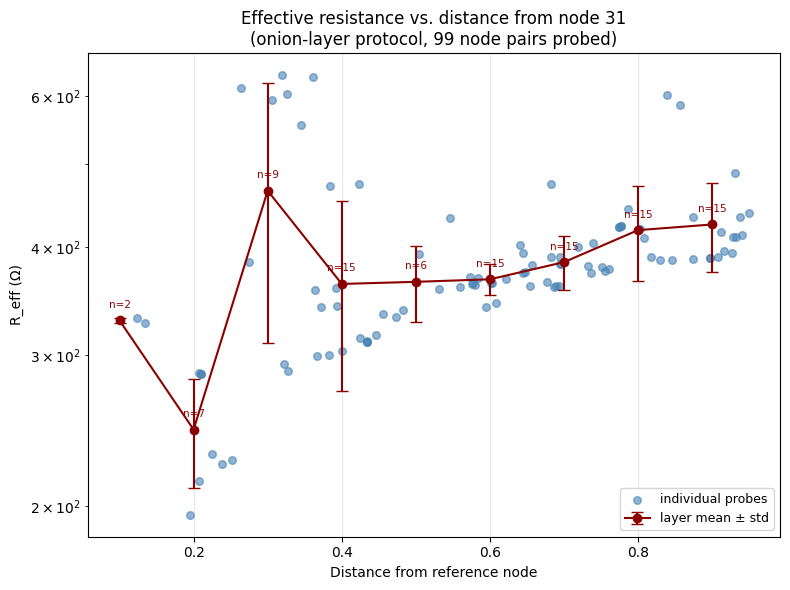

In [30]:
fig = plot_r_eff_vs_distance(records, reference_node=reference_node)
exp_manager.save_figure(fig, 'r_eff_vs_distance.png')
plt.show()

Each blue dot is one `(reference_node, j)` measurement. The red line
shows the mean ± standard deviation within each shell; only `j` varies.


---
## 6b. Validating the pinv fast path

`run_onion_protocol_pinv` computes one Laplacian pseudoinverse per network
and obtains all reference-to-node resistances from it. This avoids a
separate dense solve for every probe in the large `(N, a, d)` sweep.

Both paths below use `R_edge = R0 * L_edge`. Section 6 capped sampling at
15 probes per shell; here the solve-based path runs uncapped so both
methods probe the same nodes. The checks require matching node sets and
disconnected-node classifications, then compare finite resistances with
a maximum relative error below `1e-6`.


In [31]:
# Section 6 already ran this protocol under the distance-dependent model, but
# capped at 15 probes per shell; the pinv path has no reason to cap anything,
# so re-run the slow path uncapped to compare the two on the exact same node set.
slow_dd_records = run_onion_protocol(
    intersections, graph, segment_to_nodes, reference_node,
    layer_distances=layer_distances, k=R0, distance_dependent=True,
    max_probes_per_layer=None, seed=0, verbose=False
)
fast_records = run_onion_protocol_pinv(
    intersections, segment_to_nodes, reference_node,
    layer_distances=layer_distances, R0=R0
)

slow_by_j = {r['node_j']: r['r_eff'] for r in slow_dd_records}
fast_by_j = {r['node_j']: r['r_eff'] for r in fast_records}
assert set(slow_by_j) == set(fast_by_j), "fast and slow paths probed different node sets"

slow_inf = {j for j, r in slow_by_j.items() if not np.isfinite(r)}
fast_inf = {j for j, r in fast_by_j.items() if not np.isfinite(r)}
assert slow_inf == fast_inf, f"disconnected-node disagreement: slow={slow_inf} fast={fast_inf}"

finite_js = [j for j in slow_by_j if j not in slow_inf]
rel_errors = [abs(fast_by_j[j] - slow_by_j[j]) / slow_by_j[j] for j in finite_js]

print(f"Compared {len(finite_js)} finite (reference_node, j) probes, distance-dependent model, R0={R0}")
print(f"  {len(slow_inf)} disconnected probe(s), agree on both sides")
print(f"Max relative error (fast vs. slow): {max(rel_errors):.2e}")
print(f"Mean relative error: {np.mean(rel_errors):.2e}")
assert max(rel_errors) < 1e-6, "pinv fast path disagrees with the solve-based path beyond tolerance"
print("PASSED: run_onion_protocol_pinv matches run_onion_protocol (distance-dependent model)")

Compared 146 finite (reference_node, j) probes, distance-dependent model, R0=1000.0
  0 disconnected probe(s), agree on both sides
Max relative error (fast vs. slow): 8.40e-13
Mean relative error: 3.31e-13
PASSED: run_onion_protocol_pinv matches run_onion_protocol (distance-dependent model)


---
## 7. Robustness across several network realizations

Repeat the onion-layer protocol on several independently generated
percolating networks (same N, a; different random seeds) and overlay the
per-layer mean curves, to see how much the R_eff-vs-distance trend varies
from one random network to another.

In [32]:
seeds = [1, 2, 3, 4, 5]
realization_curves = {}

for seed in seeds:
    res_s, attempts_s = generate_percolating_network(N, a, k_uniform=R0, seed=seed)
    inter_s = res_s['pre_merge_intersections']
    seg_s = res_s['pre_merge_segment_to_nodes']
    graph_s = build_graph_from_segments(len(inter_s), seg_s)
    ref_s = res_s['pre_merge_source_nodes'][0]

    recs = run_onion_protocol(inter_s, graph_s, seg_s, ref_s,
                              layer_distances=layer_distances, k=R0,
                              distance_dependent=True,
                              max_probes_per_layer=15, seed=0, verbose=False)
    finite = [r for r in recs if np.isfinite(r['r_eff'])]
    layer_means = {}
    for d in layer_distances:
        vals = [r['r_eff'] for r in finite if r['layer_distance'] == d]
        if vals:
            layer_means[d] = float(np.mean(vals))
    realization_curves[seed] = layer_means
    print(f"seed={seed}: attempts={attempts_s}, nodes={len(inter_s)}, "
         f"layers covered={len(layer_means)}, whole-face R_eff="
         f"{distance_dependent_impedance(res_s, R0)['impedance']:.4f}")

seed=1: attempts=1, nodes=107, layers covered=9, whole-face R_eff=192.7712
seed=2: attempts=1, nodes=151, layers covered=9, whole-face R_eff=201.9751
seed=3: attempts=1, nodes=250, layers covered=9, whole-face R_eff=99.1542
seed=4: attempts=1, nodes=212, layers covered=8, whole-face R_eff=94.5440
seed=5: attempts=1, nodes=127, layers covered=9, whole-face R_eff=210.8266


  [OK] Figure saved: realizations_overlay.png


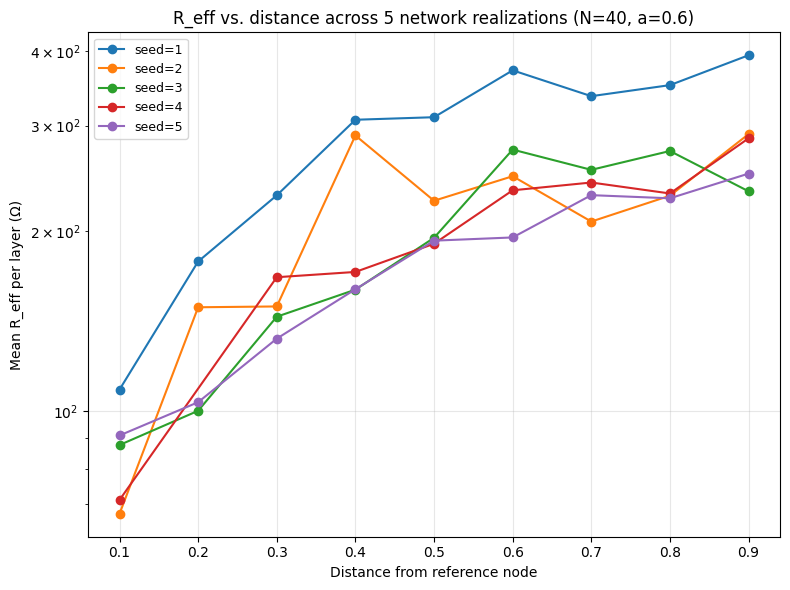

In [33]:
fig, ax = plt.subplots(figsize=(8, 6))
for seed, layer_means in realization_curves.items():
    ds = sorted(layer_means)
    ax.plot(ds, [layer_means[d] for d in ds], marker='o', label=f'seed={seed}')
ax.set_yscale('log')
ax.set_xlabel('Distance from reference node')
ax.set_ylabel('Mean R_eff per layer (Ω)')
ax.set_title(f'R_eff vs. distance across {len(seeds)} network realizations (N={N}, a={a})')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
exp_manager.save_figure(fig, 'realizations_overlay.png')
plt.show()

---
## 8. Point probe vs. whole-face resistance

Merging an entire source/drain face into one terminal (`merge_boundary_nodes`,
used everywhere else in this project) opens up many more parallel current
paths than a single point probe does. Shorting nodes together can only lower
the resistance between them (Rayleigh's monotonicity law), so probing one
source-face node against one drain-face node must read a **higher** R_eff than
the whole-face merged value, in every realization and under either resistance
model. The cell below asserts exactly that for both.

That inequality is also a live regression test for the merge geometry. Under
the distance-dependent model it used to **fail**, because `merge_boundary_nodes`
parks the merged terminal at the *average position* of the face nodes, and the
whole-face solve then re-measured every edge touching that terminal against the
centroid: wire segments that never moved silently changed resistance, inflating
the whole-face R_eff by 2-17% depending on the realization. Shorting a face is
node *identification* -- the nodes are tied by an ideal conductor and the wires
keep their real lengths -- so `distance_dependent_impedance` now measures edge
lengths on the pre-merge geometry (`impedance_calculator.merged_edge_true_lengths`,
which also combines collapsed parallel edges as parallel conductances). With
that fixed, the physical inequality holds again on every seed, which is why the
assertion below covers both models rather than just the uniform one.

In [34]:
print(f"{'seed':>5} | {'whole-face':>11} | {'point probe':>11} | ratio  ||  "
      f"{'whole-face':>11} | {'point probe':>11} | ratio")
print(f"{'':>5} | {'-- distance-dependent (R_edge = R0*L) --':^41}  ||  "
      f"{'-- uniform (R_edge = R0) --':^41}")
print("-" * 116)

for seed in seeds:
    res_s, _ = generate_percolating_network(N, a, k_uniform=R0, seed=seed)
    inter_s = res_s['pre_merge_intersections']
    seg_s = res_s['pre_merge_segment_to_nodes']
    graph_s = build_graph_from_segments(len(inter_s), seg_s)
    i0 = res_s['pre_merge_source_nodes'][0]
    j0 = res_s['pre_merge_drain_nodes'][0]

    point_dd = measure_r_eff(inter_s, graph_s, seg_s, i0, j0,
                             k=R0, distance_dependent=True)['impedance']
    face_dd = distance_dependent_impedance(res_s, R0)['impedance']
    point_uni = measure_r_eff(inter_s, graph_s, seg_s, i0, j0, k=R0)['impedance']
    face_uni = res_s['impedance']

    print(f"{seed:>5} | {face_dd:>11.4f} | {point_dd:>11.4f} | {point_dd/face_dd:>5.2f}x  ||  "
          f"{face_uni:>11.4f} | {point_uni:>11.4f} | {point_uni/face_uni:>5.2f}x")

    assert point_dd >= face_dd, (
        f"seed={seed}: distance-dependent point probe R_eff ({point_dd:.4f}) fell below the "
        f"whole-face value ({face_dd:.4f}); shorting a face can only lower R_eff, so this "
        f"means the merged network is not the pre-merge network with its faces shorted -- "
        f"check that distance_dependent_impedance is still measuring edge lengths on the "
        f"pre-merge geometry")
    assert point_uni >= face_uni, (
        f"seed={seed}: uniform point probe R_eff fell below the whole-face value")

print("\nPASSED: point probe R_eff >= whole-face R_eff in every realization, "
      "under both resistance models.")

 seed |  whole-face | point probe | ratio  ||   whole-face | point probe | ratio
      | -- distance-dependent (R_edge = R0*L) --   ||         -- uniform (R_edge = R0) --       
--------------------------------------------------------------------------------------------------------------------
    1 |    192.7712 |    431.9099 |  2.24x  ||    1841.0288 |   3885.8404 |  2.11x
    2 |    201.9751 |    356.4403 |  1.76x  ||    2174.2970 |   4101.3809 |  1.89x
    3 |     99.1542 |    290.1326 |  2.93x  ||    1500.4535 |   4831.0055 |  3.22x
    4 |     94.5440 |    351.6199 |  3.72x  ||    1257.8158 |   4740.9828 |  3.77x
    5 |    210.8266 |    391.4666 |  1.86x  ||    2775.4003 |   5272.5340 |  1.90x

PASSED: point probe R_eff >= whole-face R_eff in every realization, under both resistance models.


---
## Save experiment summary

In [35]:
summary = {
    'network_params': {'N': N, 'a': a, 'R0': R0},
    'resistance_model': 'distance_dependent (R_edge = R0 * L_edge)',
    'validation': 'PASSED (ring + uneven-spacing chain closed-form checks, distance-dependent)',
    'manual_probes': exp2_records,
    'onion_protocol': {
        'reference_node': reference_node,
        'layer_distances': layer_distances,
        'n_probes': len(records),
    },
    'realizations': {str(seed): layer_means for seed, layer_means in realization_curves.items()},
}
exp_manager.save_json(summary, 'experiment_summary.json')

  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'


'/content/drive/MyDrive/ColabProject/experiments/exp_2/experiment_summary.json'